# 04 · Decision Tree (California Housing)

**Input:** `../data/processed/california_housing_clean.csv` · **Target:** `MedHouseVal` (regression, ឯកតា $100,000)

## 1. Goal
ទាយតម្លៃផ្ទះដោយ **សំណួរ បាទ/ទេ ជាបន្តបន្ទាប់** ("ចំណូលលើសពី 5 ឬអត់? ... នៅខាងលិច longitude −118 ឬអត់?")។ Decision Tree ត្រូវបានប្រើនៅកន្លែងដែលត្រូវ **ពន្យល់ការសម្រេចចិត្ត**
ហើយជាគ្រឹះរបស់ Random Forest និង Gradient Boosting ដែលជា models ខ្លាំងបំផុតសម្រាប់ tabular data។

## Concept
**ឧបមា "20 questions":** ល្បែងទាយរបស់ដោយសួរសំណួរ បាទ/ទេ។ អ្នកលេងពូកែសួរសំណួរដែល **បំបែកលទ្ធភាពបានច្រើនបំផុត** ជាមុន មិនមែនសំណួរលម្អិតពេកទេ។
Decision Tree ធ្វើដូចគ្នា: នៅ node នីមួយៗ វាសាកគ្រប់ feature និងគ្រប់ threshold ហើយជ្រើសសំណួរដែលបំបែក data ទៅជាពីរក្រុម ដែល **តម្លៃក្នុងក្រុមនីមួយៗដូចគ្នាបំផុត**។

**Regression tree** វាស់ "ភាពមិនដូចគ្នា" ដោយ **squared error** (MSE) នៃ node: `MSE = mean((y − mean(y))²)`
(Classification ក្នុង Titanic ប្រើ Gini)។
- Node ដែលមានតម្លៃទាំងអស់ដូចគ្នា (ឧ. 2.0, 2.0, 2.0) → MSE = 0 (សុទ្ធ)។
- Node ដែលលាយ (ឧ. 0.5, 2.0, 4.5) → MSE ខ្ពស់ (ទាយពិបាក)។

Tree ជ្រើស split ដែលធ្វើឲ្យ MSE (មធ្យមតាមទំហំ) របស់ nodes កូនទាំងពីរ **ធ្លាក់ចុះច្រើនបំផុត**។ Leaf (ស្លឹក) នីមួយៗទាយ **មធ្យម** នៃ `MedHouseVal` របស់ training rows ដែលធ្លាក់ក្នុងវា។
ដូច្នេះ tree ទាយបានតែ **តម្លៃមិនបន្ត** ចំនួនស្មើនឹងចំនួន leaves (ជាជណ្តើរ មិនមែនបន្ទាត់រលោងទេ)។

Import libraries។

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor, plot_tree

pd.set_option("display.max_columns", None)
BLUE, ORANGE, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#e6e5e1"

def style(ax):
    """Light grid, no top/right spines."""
    ax.grid(color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
    ax.tick_params(colors=MUTED, labelsize=9)

def evaluate(model, A, B):
    """Train and test MAE / RMSE / R2 for a fitted model. A = train features, B = test features."""
    out = {}
    for split, Xs, ys in [("train", A, y_train), ("test", B, y_test)]:
        pred = model.predict(Xs)
        out[f"{split} MAE"] = mean_absolute_error(ys, pred)
        out[f"{split} RMSE"] = np.sqrt(mean_squared_error(ys, pred))
        out[f"{split} R2"] = r2_score(ys, pred)
    return out

Load clean data ហើយ split ដូច Lesson 2 (`test_size=0.2`, `random_state=42`)។

In [2]:
df = pd.read_csv("../data/processed/california_housing_clean.csv")
X = df.drop(columns=["MedHouseVal"])
y = df["MedHouseVal"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
feature_names = X.columns.tolist()
X_train.shape, X_test.shape

((15546, 8), (3887, 8))

## 2. Preprocessing: NO scaling (and nothing else needed)
Data នេះគ្មាន missing values និងគ្មាន categorical columns (notebook 01) ដូច្នេះ trees អាចប្រើ `X_train` ដោយផ្ទាល់ គ្មាន `ColumnTransformer` ទេ។

**ហេតុអ្វី trees មិនត្រូវការ scaling?** Tree សួរតែសំណួរដូចជា "`MedInc` ≤ 5.03?" លើ feature **មួយម្តង**។ វាមិនគណនា distance ហើយមិនបូក features ចូលគ្នាទេ។
បើយើងគុណ `Population` នឹង 1000 threshold គ្រាន់តែក្លាយជាលេខធំជាងដដែល ហើយ rows ដដែលទៅឆ្វេង/ស្តាំដដែល។ លំដាប់នៃតម្លៃប៉ុណ្ណោះដែលសំខាន់។
ដើម្បីប្រៀបធៀបជាមួយ Linear Regression និង KNN នៅចុងក្រោយ យើង scale data ដាច់ដោយឡែកសម្រាប់ពួកវា (fit លើ train តែប៉ុណ្ណោះ)។

In [3]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)   # only for Linear Regression and KNN in section 8
X_test_s = scaler.transform(X_test)
X_train_s.shape

(15546, 8)

## 3. Unlimited tree (max_depth=None)
គ្មានដែនកំណត់ tree បន្តបំបែករហូតដល់ leaf នីមួយៗសុទ្ធ (ជាធម្មតា 1 row ក្នុងមួយ leaf)។ `random_state=42` ធ្វើឲ្យលទ្ធផលដដែល (ពេល splits ពីរល្អស្មើគ្នា)។

In [4]:
tree_full = DecisionTreeRegressor(random_state=42).fit(X_train, y_train)
{"train R2": round(tree_full.score(X_train, y_train), 4), "test R2": round(tree_full.score(X_test, y_test), 4),
 "leaves": int(tree_full.get_n_leaves()), "depth": int(tree_full.get_depth()), "training rows": len(X_train)}

{'train R2': 1.0,
 'test R2': 0.5464,
 'leaves': 15427,
 'depth': 34,
 'training rows': 15546}

**Overfitting ច្បាស់:** train R² = **1.000** ប៉ុន្តែ test R² ត្រឹមតែ **0.546**។ Tree មាន **15,427 leaves** សម្រាប់ training rows 15,546 គឺស្ទើរតែ 1 row ក្នុងមួយ leaf ហើយជម្រៅ 34 សំណួរ។
វាបាន **ទន្ទេញ** សង្កាត់នីមួយៗ រួមទាំង noise ជំនួសឲ្យការរៀន pattern ទូទៅ។ ពិន្ទុ test របស់វា **អន់ជាង Linear Regression** (0.636) ទៅទៀត។

## 4. Effect of max_depth
`max_depth` កំណត់ចំនួនសំណួរច្រើនបំផុតពីឫសដល់ស្លឹក។ សាកល្បង 1 ដល់ 20 ហើយមើល **RMSE** (ទាបជាង = ល្អជាង)។

In [5]:
rows = []
for d in range(1, 21):
    t = DecisionTreeRegressor(max_depth=d, random_state=42).fit(X_train, y_train)
    rows.append({"max_depth": d, "train RMSE": np.sqrt(mean_squared_error(y_train, t.predict(X_train))),
                 "test RMSE": np.sqrt(mean_squared_error(y_test, t.predict(X_test))),
                 "test R2": t.score(X_test, y_test), "leaves": t.get_n_leaves()})
depth_results = pd.DataFrame(rows).set_index("max_depth")
depth_results.round(4).T

max_depth,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
train RMSE,0.8263,0.7550,0.6960,0.6618,0.6217,0.5886,0.5510,0.5022,0.4619,0.4179,0.3738,0.3282,0.2862,0.2459,0.2064,0.1717,0.1402,0.1140,0.0895,0.0672
test RMSE,0.8386,0.7657,0.7115,0.6778,0.6403,0.6166,0.5891,0.5622,0.5614,0.5688,0.5814,0.5928,0.6110,0.6183,0.6273,0.6390,0.6385,0.6491,0.6381,0.6475
test R2,0.2657,0.3878,0.4715,0.5203,0.5719,0.6031,0.6377,0.6701,0.6709,0.6622,0.6470,0.6331,0.6102,0.6009,0.5892,0.5737,0.5743,0.5601,0.5749,0.5623
leaves,2.0000,4.0000,8.0000,16.0000,32.0000,64.0000,126.0000,244.0000,451.0000,791.0000,1325.0000,2076.0000,3022.0000,4185.0000,5485.0000,6840.0000,8262.0000,9626.0000,10876.0000,11983.0000


Plot train ទល់នឹង test RMSE។

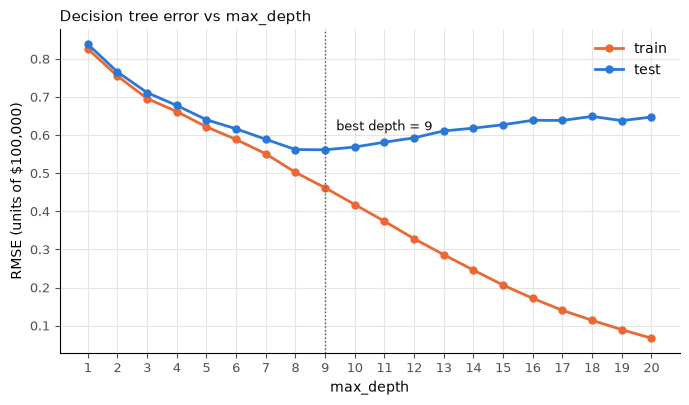

9

In [6]:
best_depth = int(depth_results["test RMSE"].idxmin())

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(depth_results.index, depth_results["train RMSE"], color=ORANGE, linewidth=2, marker="o", markersize=5, label="train")
ax.plot(depth_results.index, depth_results["test RMSE"], color=BLUE, linewidth=2, marker="o", markersize=5, label="test")
ax.axvline(best_depth, color=MUTED, linewidth=1, linestyle=":")
ax.annotate(f"best depth = {best_depth}", (best_depth, depth_results["test RMSE"].min()), xytext=(8, 14),
            textcoords="offset points", color=INK, fontsize=9)
ax.set_xticks(depth_results.index); ax.set_xlabel("max_depth"); ax.set_ylabel("RMSE (units of $100,000)")
ax.set_title("Decision tree error vs max_depth", loc="left", fontsize=11, color=INK)
ax.legend(frameon=False); style(ax)
plt.show()
best_depth

**អានក្រាហ្វ:**
- **ខាងឆ្វេង (depth 1–4):** train និង test RMSE ខ្ពស់ និងជិតគ្នា (0.83 / 0.84 នៅ depth 1)។ Tree សាមញ្ញពេក → **Underfitting**។
- **កំពូល (depth 8–9):** test RMSE ទាបបំផុតនៅ **depth 9** (0.561, R² 0.671); depth 8 ស្ទើរតែដូចគ្នា (0.562)។
- **ខាងស្តាំ:** train RMSE ធ្លាក់ទៅជិត 0 (0.067 នៅ depth 20) ខណៈ test RMSE **កើនឡើងវិញ** (0.648)។ សំណួរបន្ថែមនីមួយៗឥឡូវនេះគឺទន្ទេញ noise → **Overfitting**។
- **គម្លាត** រវាងបន្ទាត់ទាំងពីរ គឺជាឧបករណ៍វាស់ Overfitting។ វាកើនឡើងជាលំដាប់តាមជម្រៅ។
- សូម្បីតែ tree តែមួយដែលល្អបំផុត (R² 0.671) ក៏ល្អជាង Linear Regression (0.636) តែបន្តិច ហើយ **អន់ជាង KNN** (0.701)។

⚠️ **ការព្រមាន (leakage ស្រាល, ដូច Lesson 3):** យើងជ្រើស depth ដោយមើល **test RMSE** ដូច្នេះ test score របស់ depth ដែលល្អបំផុតគឺសុទិដ្ឋិនិយមបន្តិច។
វិធីត្រឹមត្រូវ: ជ្រើស hyperparameters ដោយ **Cross-Validation លើ train តែប៉ុណ្ណោះ** → Lesson 8 (Step 8: validation curve)។

## 5. A small tree you can read: max_depth=3
Tree តូចដែលមនុស្សអានបាន។ ក្នុង node នីមួយៗ: សំណួរ, `squared_error` (MSE របស់ node), `samples` (ចំនួន training rows) និង `value` = **តម្លៃទាយ** (មធ្យមរបស់ rows ក្នុង node)។
**ឆ្វេង = បាទ (លក្ខខណ្ឌពិត), ស្តាំ = ទេ។** ពណ៌កាន់តែចាស់ = `value` កាន់តែខ្ពស់ (ផ្ទះថ្លៃជាង)។

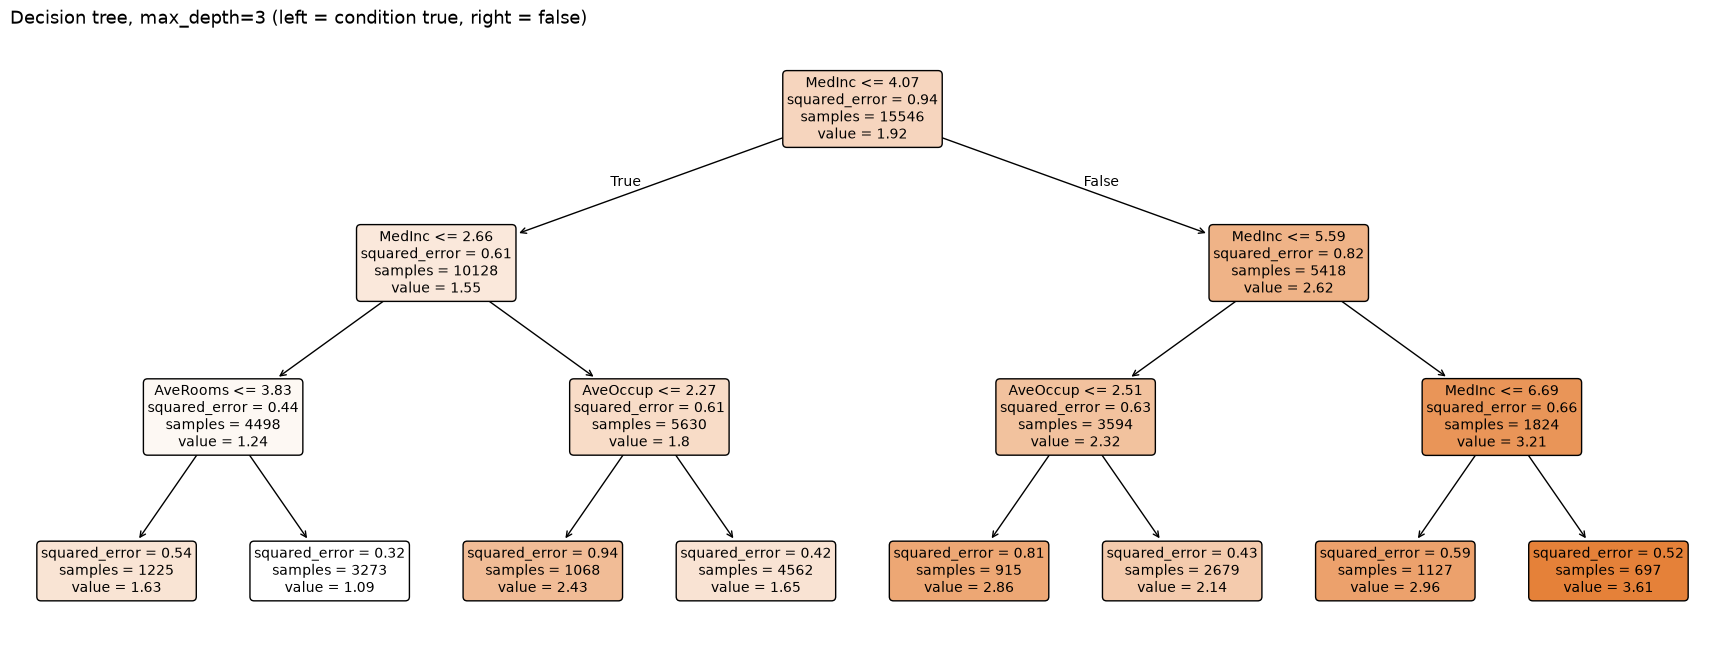

In [7]:
tree3 = DecisionTreeRegressor(max_depth=3, random_state=42).fit(X_train, y_train)

fig, ax = plt.subplots(figsize=(22, 8))
plot_tree(tree3, feature_names=feature_names, filled=True, rounded=True, impurity=True, precision=2, fontsize=10, ax=ax)
ax.set_title("Decision tree, max_depth=3 (left = condition true, right = false)", loc="left", fontsize=13)
plt.show()

**ដើរតាម splits** (ឆ្វេង = `≤` = បាទ):

1. **ឫស: `MedInc ≤ 4.07`?** 15,546 សង្កាត់ ជាមួយ value (តម្លៃមធ្យម) 1.92 និង MSE 0.94។ នេះជាសំណួរដែលបំបែកបានល្អបំផុត: សង្កាត់ចំណូលទាប 10,128 ទៅឆ្វេង (មធ្យម 1.55)
   ហើយចំណូលខ្ពស់ 5,418 ទៅស្តាំ (មធ្យម 2.62)។ Tree រកឃើញដោយខ្លួនឯងថា **ចំណូល** ជា feature សំខាន់បំផុត។
2. **សាខាចំណូលទាប:** `MedInc ≤ 2.66`? សង្កាត់ចំណូលទាបខ្លាំង (4,498) មធ្យម 1.24។ បន្ទាប់មក `AveRooms ≤ 3.83`: ផ្ទះតូចៗ (បន្ទប់តិច) 1,225 → 1.63 ទល់នឹង 3,273 → **1.09** (ថោកបំផុត)។
3. **សាខាចំណូលខ្ពស់:** `MedInc ≤ 5.59`? ហើយបន្ទាប់មក `MedInc ≤ 6.69`: សង្កាត់ចំណូលខ្ពស់បំផុត (`MedInc > 6.69`, 697 សង្កាត់) មាន value **3.61** ($361,000) ជា leaf ថ្លៃបំផុត។
4. `AveOccup` ក៏ត្រូវបានប្រើពីរដង៖ គ្រួសារតូចជាង (`AveOccup` ទាប) ទាក់ទងនឹងតម្លៃខ្ពស់ជាង (2.43 ទល់ 1.65 ក្នុងក្រុមចំណូលមធ្យមទាប)។

**ចំណុចគួរកត់សម្គាល់:** tree depth 3 **មិនប្រើ `Latitude` ឬ `Longitude` សោះ** ហើយមាន leaves ត្រឹម 8 ដូច្នេះវាទាយបានតែ **8 តម្លៃខុសគ្នា** (ជណ្តើរ 8 កម្រិត)។
ហេតុផល: Tree ជ្រើស split ល្អបំផុត **ម្តងមួយជំហាន** (greedy)។ នៅកម្រិតរាក់ ការបំបែកតាមចំណូលបន្ថយ MSE បានច្រើនជាងការបំបែកតាមទីតាំងតែមួយ ប៉ុន្តែទីតាំងសំខាន់ក្នុងការរួមបញ្ចូលគ្នាជាមួយចំណូល ដែល tree ជ្រៅជាងអាចរកឃើញ។

## 6. Final tree at the best depth
ប្រើ `max_depth = best_depth` ពី Step 4។ ពិនិត្យ residual plot និង predicted vs actual។ ចំណាំថា tree ទាយបានតែ **តម្លៃមិនបន្ត** (ជាជណ្តើរ)។

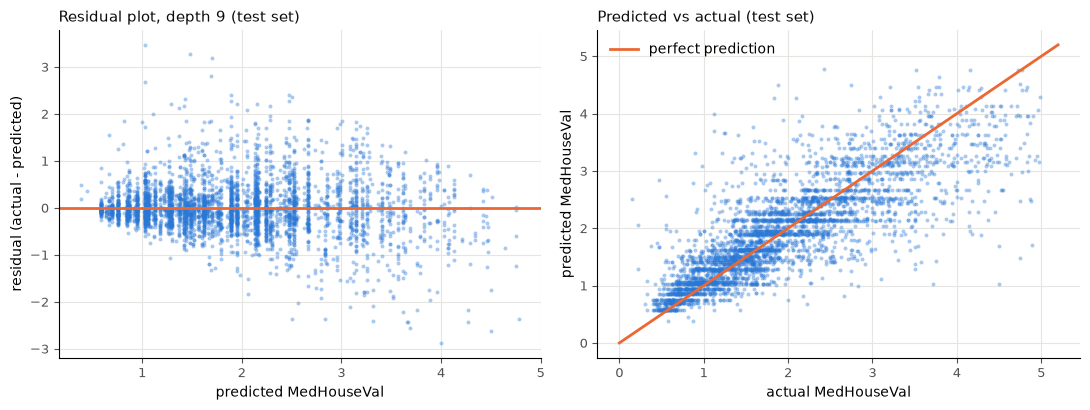

In [8]:
tree_best = DecisionTreeRegressor(max_depth=best_depth, random_state=42).fit(X_train, y_train)
pred_test = tree_best.predict(X_test)
resid = y_test - pred_test

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))
ax1.scatter(pred_test, resid, s=8, color=BLUE, alpha=0.4, linewidth=0)
ax1.axhline(0, color=ORANGE, linewidth=2)
ax1.set_xlabel("predicted MedHouseVal"); ax1.set_ylabel("residual (actual - predicted)")
ax1.set_title(f"Residual plot, depth {best_depth} (test set)", loc="left", fontsize=11, color=INK); style(ax1)

ax2.scatter(y_test, pred_test, s=8, color=BLUE, alpha=0.4, linewidth=0)
lims = [0, 5.2]
ax2.plot(lims, lims, color=ORANGE, linewidth=2, label="perfect prediction")
ax2.set_xlabel("actual MedHouseVal"); ax2.set_ylabel("predicted MedHouseVal")
ax2.set_title("Predicted vs actual (test set)", loc="left", fontsize=11, color=INK)
ax2.legend(frameon=False); style(ax2)
fig.tight_layout()
plt.show()

In [9]:
{"distinct predictions, depth 3": int(len(np.unique(tree3.predict(X_test)))),
 f"distinct predictions, depth {best_depth}": int(len(np.unique(pred_test))),
 "distinct predictions, unlimited": int(len(np.unique(tree_full.predict(X_test)))),
 "distinct actual values in test": int(y_test.nunique())}

{'distinct predictions, depth 3': 8,
 'distinct predictions, depth 9': 305,
 'distinct predictions, unlimited': 1960,
 'distinct actual values in test': 2144}

**អានលទ្ធផល:**
- **Residual plot:** ចំណុចតម្រៀបជា **ឈរ** (vertical stripes) ព្រោះ tree ទាយបានតែតម្លៃមិនបន្ត។ នៅតែមានរាងចីវលោ (កំហុសធំជាងសម្រាប់តម្លៃទាយខ្ពស់)។
- **Predicted vs actual:** ចំណុចតម្រៀបជា **ជួរដេក** (horizontal stripes) ព្រោះ leaf នីមួយៗទាយតម្លៃតែមួយ។ សម្រាប់សង្កាត់ថ្លៃ (actual > 3.5) ចំណុចភាគច្រើននៅក្រោមបន្ទាត់: នៅតែទាយទាបពេក។
- **Tree depth 3** ទាយបានតែ 8 តម្លៃ, **depth 9** ទាយបាន 305 តម្លៃ, **unlimited** ទាយបាន 1,960 តម្លៃ ស្ទើរតែប៉ុន្មានតម្លៃពិតខុសគ្នាក្នុង test (2,144)។
  នោះបង្ហាញថា tree unlimited ស្ទើរតែ "ចម្លង" តម្លៃពី training: ទន្ទេញ។

## 7. Feature importances
Importance = feature នោះបន្ថយ MSE សរុបបានប៉ុន្មាន (គិតតាមចំនួន rows ដែលឆ្លងកាត់ split)។ ផលបូក = 1។ Features ដែល tree មិនបានប្រើ មាន importance 0។

In [10]:
importances = pd.DataFrame({
    f"tree depth {best_depth}": tree_best.feature_importances_,
    "tree depth 3": tree3.feature_importances_,
    "tree unlimited": tree_full.feature_importances_,
}, index=feature_names).sort_values(f"tree depth {best_depth}", ascending=False)
importances.round(3)

,tree depth 9,tree depth 3,tree unlimited
MedInc,0.558,0.839,0.454
AveOccup,0.135,0.125,0.132
Longitude,0.123,0.000,0.132
Latitude,0.096,0.000,0.114
HouseAge,0.044,0.000,0.053
AveRooms,0.029,0.037,0.052
Population,0.008,0.000,0.032
AveBedrms,0.008,0.000,0.029


Bar chart នៃ importances របស់ tree depth ល្អបំផុត។

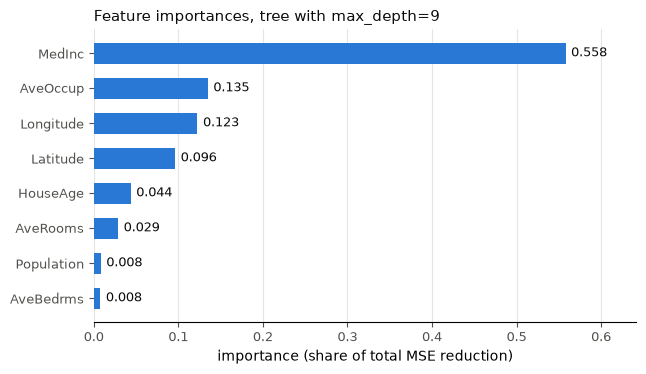

In [11]:
used = importances[f"tree depth {best_depth}"].sort_values()
fig, ax = plt.subplots(figsize=(7, 3.8))
bars = ax.barh(used.index, used.values, color=BLUE, height=0.6)
ax.bar_label(bars, fmt="%.3f", padding=4, color=INK, fontsize=9)
ax.set_xlabel("importance (share of total MSE reduction)")
ax.set_title(f"Feature importances, tree with max_depth={best_depth}", loc="left", fontsize=11, color=INK)
ax.set_xlim(0, used.max() * 1.15)
ax.grid(axis="x", color=GRID, linewidth=0.8); ax.set_axisbelow(True)
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.tick_params(colors=MUTED, labelsize=9)
plt.show()

**ប្រៀបធៀបជាមួយ coefficients របស់ Linear Regression (Lesson 2):**
- **យល់ស្របគ្នា:** `MedInc` ជា feature សំខាន់បំផុតឆ្ងាយ (importance 0.558 នៅ depth 9)។
- **ទីតាំងសំខាន់:** `Longitude` (0.123) និង `Latitude` (0.096) បូកគ្នាប្រហែល 0.22 ដែលជិត `AveOccup` (0.135) ហើយធំជាង `HouseAge`, `AveRooms`, `Population`, `AveBedrms` បូកគ្នា។
  Tree depth 3 មិនប្រើទីតាំងសោះ (0.000) ប៉ុន្តែ tree ជ្រៅជាងប្រើវា។
- **ខុសគ្នា 1:** Importance **គ្មានសញ្ញា** (វិជ្ជមាន/អវិជ្ជមាន)។ វាប្រាប់ថា feature មានប្រយោជន៍ប៉ុណ្ណា មិនមែនថាវាបង្កើន ឬបន្ថយតម្លៃទេ។ ត្រូវមើល coefficients (Lesson 2) ឬ tree ដើម្បីដឹងទិស។
- **ខុសគ្នា 2:** Tree ចាប់បាន **interaction**: ទីតាំងសំខាន់ **ក្នុងក្រុមចំណូលខ្ពស់** (ឆ្នេរសមុទ្រ ទល់នឹងដីគោក)។ Linear Regression ផ្តល់ coefficient តែមួយសម្រាប់ `Latitude` ដែលអនុវត្តលើគ្រប់គ្នា។
- **ខុសគ្នា 3:** Tree unlimited ផ្តល់ importance ស្មើគ្នាជាងសម្រាប់ features តូចៗ (`Population` 0.032, `AveBedrms` 0.029 ទល់ 0.008 នៅ depth 9) ព្រោះ features ដែលមានតម្លៃច្រើនផ្តល់ឱកាសច្រើនក្នុងការបំបែក noise។

## 8. Comparison with earlier models
Split ដដែល។ Linear Regression និង KNN ប្រើ data ដែល scale (ដូច Lessons 2 និង 3); trees ប្រើ data គ្មាន scaling។

In [12]:
comparison = pd.DataFrame({
    "Baseline (mean)": evaluate(DummyRegressor(strategy="mean").fit(X_train_s, y_train), X_train_s, X_test_s),
    "Linear Regression": evaluate(LinearRegression().fit(X_train_s, y_train), X_train_s, X_test_s),
    "KNN (k=15)": evaluate(KNeighborsRegressor(n_neighbors=15).fit(X_train_s, y_train), X_train_s, X_test_s),
    "Tree (unlimited)": evaluate(tree_full, X_train, X_test),
    f"Tree (max_depth={best_depth})": evaluate(tree_best, X_train, X_test),
    "Tree (max_depth=3)": evaluate(tree3, X_train, X_test),
}).T.round(3)
comparison

,train MAE,train RMSE,train R2,test MAE,test RMSE,test R2
Baseline (mean),0.779,0.971,0.000,0.790,0.979,-0.000
Linear Regression,0.438,0.587,0.634,0.439,0.590,0.636
KNN (k=15),0.354,0.498,0.737,0.380,0.535,0.701
Tree (unlimited),0.000,0.000,1.000,0.427,0.659,0.546
Tree (max_depth=9),0.324,0.462,0.774,0.385,0.561,0.671
Tree (max_depth=3),0.529,0.696,0.486,0.545,0.711,0.471


**អានលទ្ធផល:**
- **Tree unlimited** មាន train R² ខ្ពស់បំផុត (1.000) ប៉ុន្តែ test R² 0.546 អន់ជាង Linear Regression → **overfitting**។
- **Tree depth 9** (R² 0.671, MAE 0.385, RMSE 0.561) ឈ្នះ Linear Regression (0.636) ប៉ុន្តែនៅតែ **អន់ជាង KNN** (0.701, MAE 0.380)។ ម្យ៉ាងទៀត train R² 0.774 ទល់ test 0.671 → នៅមានគម្លាត។
- **Tree depth 3** ងាយអាន ប៉ុន្តែ underfit (test R² 0.471, អន់ជាង Linear)។ នេះជា trade-off រវាង **ការអានបាន** និង **ភាពត្រឹមត្រូវ**។
- Tree តែមួយមិនឈ្នះ models ពិតទេ។ ដំណោះស្រាយ: រួមបញ្ចូល trees ច្រើន (Lesson 5: Random Forest, Lesson 7: XGBoost)។

## 9. Predict for the two made-up neighbourhoods
សង្កាត់ដូចគ្នាពី Lessons 2 និង 3។ ការទាយរបស់ tree = **មធ្យម** នៃ training rows ក្នុង leaf ដែលសង្កាត់ធ្លាក់ចូល។

In [13]:
new_neighbourhoods = pd.DataFrame([
    {"MedInc": 8.0, "HouseAge": 25, "AveRooms": 6.5, "AveBedrms": 1.0, "Population": 1500,
     "AveOccup": 2.8, "Latitude": 34.05, "Longitude": -118.40},
    {"MedInc": 2.2, "HouseAge": 35, "AveRooms": 4.8, "AveBedrms": 1.1, "Population": 1800,
     "AveOccup": 3.4, "Latitude": 36.75, "Longitude": -119.80},
], index=["high income, Los Angeles coast", "low income, inland Central Valley"])
pd.DataFrame({
    "price (depth 3)": tree3.predict(new_neighbourhoods).round(2),
    f"price (depth {best_depth})": tree_best.predict(new_neighbourhoods).round(2),
    "price (unlimited)": tree_full.predict(new_neighbourhoods).round(2),
}, index=new_neighbourhoods.index)

,price (depth 3),price (depth 9),price (unlimited)
"high income, Los Angeles coast",3.61,4.29,4.77
"low income, inland Central Valley",1.09,0.70,0.59


**Decision path:** សំណួរដែលសង្កាត់ម្នាក់ៗបានឆ្លើយ ពីឫសដល់ស្លឹក (tree depth 3)។ ជាដំបូង សង្កាត់ Los Angeles ដែលមានចំណូលខ្ពស់។

In [14]:
def decision_path(tree, row):
    t = tree.tree_
    node, steps = 0, []
    while t.children_left[node] != -1:                      # until we reach a leaf
        f, thr = t.feature[node], t.threshold[node]
        value = row[f]
        go_left = value <= thr
        steps.append({"question": f"{feature_names[f]} <= {thr:.2f} ?", "neighbourhood value": round(float(value), 2),
                      "answer": "yes -> left" if go_left else "no -> right"})
        node = t.children_left[node] if go_left else t.children_right[node]
    steps.append({"question": "LEAF", "neighbourhood value": "",
                  "answer": f"predict {t.value[node][0][0]:.2f} (mean of {t.n_node_samples[node]} training block groups)"})
    return pd.DataFrame(steps)

decision_path(tree3, new_neighbourhoods.to_numpy()[0])

,question,neighbourhood value,answer
0,MedInc <= 4.07 ?,8.0,no -> right
1,MedInc <= 5.59 ?,8.0,no -> right
2,MedInc <= 6.69 ?,8.0,no -> right
3,LEAF,,predict 3.61 (mean of 697 training block groups)


សង្កាត់ចំណូលទាប នៅ Central Valley។

In [15]:
decision_path(tree3, new_neighbourhoods.to_numpy()[1])

,question,neighbourhood value,answer
0,MedInc <= 4.07 ?,2.2,yes -> left
1,MedInc <= 2.66 ?,2.2,yes -> left
2,AveRooms <= 3.83 ?,4.8,no -> right
3,LEAF,,predict 1.09 (mean of 3273 training block groups)


**អានលទ្ធផល:** Tree depth 3 ទាយសង្កាត់ Los Angeles = **3.61** និង Central Valley = **1.09**។ Tree depth 9 ទាយ 4.29 និង 0.70, tree unlimited ទាយ 4.77 និង 0.59។
ការទាយរបស់ trees ខុសគ្នាច្រើន (ពី 3.61 ដល់ 4.77) ដែលបង្ហាញថា tree តែមួយ **មិនស្ថិតស្ថេរ** (variance ខ្ពស់)។

**Decision path (depth 3):**
- សង្កាត់ Los Angeles ឆ្លើយ "ទេ" ទាំង 3 សំណួរ: `MedInc = 8.0` លើស 4.07, 5.59 និង 6.69 → leaf ដែលមាន **697** សង្កាត់ហ្វឹកហាត់ → ទាយ **3.61**។
- សង្កាត់ Central Valley ឆ្លើយ "បាទ" ចំពោះ `MedInc ≤ 4.07` និង `MedInc ≤ 2.66` បន្ទាប់មក "ទេ" ចំពោះ `AveRooms ≤ 3.83` (វាមាន 4.8) → leaf ដែលមាន **3,273** សង្កាត់ → ទាយ **1.09**។

នេះជាចំណុចខ្លាំងរបស់ Decision Tree: យើងអាច **ពន្យល់ការទាយនីមួយៗ** ជាសំណួរដែលមនុស្សយល់បាន។ (ប៉ុន្តែ tree depth 3 មិនប្រើទីតាំងទេ ដូច្នេះសង្កាត់ LA ដែលមាន `MedInc = 8` ត្រូវបានចាត់ថ្នាក់ដូចគ្នាទៅនឹងសង្កាត់ចំណូលខ្ពស់ណាក៏បាន ទោះនៅកន្លែងណា។)

## Lesson summary
- **Decision Tree** = សំណួរ បាទ/ទេ ជាបន្តបន្ទាប់។ Split នីមួយៗត្រូវបានជ្រើសដើម្បីបន្ថយ **squared error (MSE)** ច្រើនបំផុត។ Leaf ទាយ **មធ្យម** នៃ target របស់ rows ក្នុង leaf។
- Tree ទាយបានតែ **តម្លៃមិនបន្ត** (ជាជណ្តើរ): depth 3 ទាយបានតែ 8 តម្លៃ។
- **មិនត្រូវការ scaling** ព្រោះ tree ប្រើតែលំដាប់នៃតម្លៃ (thresholds) ហើយ data នេះគ្មាន missing/categorical ដូច្នេះមិនត្រូវការ preprocessing សោះ។
- **Tree គ្មានដែនកំណត់ overfit ខ្លាំង** (train R² 1.000, test 0.546, 15,427 leaves)។ `max_depth` ជា hyperparameter ដែលគ្រប់គ្រង bias/variance: ល្អបំផុតប្រហែល depth 9 (test R² 0.671, MAE 0.385, RMSE 0.561)។
- ជ្រើស depth ដោយ test set ជា leakage ស្រាល → Cross-Validation (Lesson 8)។
- **Tree តូចអានបាន**: depth 3 រកឃើញថាចំណូលជាសំណួរដំបូង ប៉ុន្តែមិនទាន់ប្រើទីតាំង (greedy splits)។
- **Feature importance** ប្រាប់ថាសំខាន់ប៉ុណ្ណា (`MedInc` 0.56) ប៉ុន្តែគ្មានទិស (សញ្ញា) ដូច coefficients។
- **Decision path** ពន្យល់ការទាយនីមួយៗ។
- Tree តែមួយមិនស្ថិតស្ថេរ (ការទាយខុសគ្នា 3.61–4.77 សម្រាប់សង្កាត់ដូចគ្នា) ហើយនៅអន់ជាង KNN → Lesson 5 (Random Forest) រួមបញ្ចូល trees ច្រើនដើម្បីដោះស្រាយបញ្ហានេះ។